# Figure S4 — Disorder profiles: metapredict V1, V2 and V3 against the top CAID3 predictors

Per-residue disorder scores along five CAID3 Disorder-PDB proteins for metapredict V1, V2 and V3 and the five best CAID3 predictors (by AUC). The bar under each trace is the Disorder-PDB reference: disordered (orange), ordered (green) and unscored (hatched grey), as in Figure 2C–E and S10. The proteins are 150–300 residues long, are ones where metapredict V3 captures the IDRs well (per-protein AUC ≥ 0.97 with metapredict 3.1.0), and span 21–67% disorder with several IDR architectures.

**How it is made.** Traces are the per-residue scores in the CAID3 submission files, with metapredict V1–V3 predicted by metapredict 3.1.0 (`data/metapredict_caid/`). The top five are ranked by AUC over the whole reference set.

**Output:** `figures/figure_S04.pdf`

In [1]:
import matplotlib.pyplot as plt

from caid3_panels import N_TOP, METAPREDICT_NAMES, load_predictions, load_reference, rank_predictors, trace_panel, trace_panel_height
from figtools import apply_style, require_metapredict_3_1, save_panel

apply_style()
require_metapredict_3_1()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

SI_PROFILE_TARGETS = ['DP04023', 'DP04296', 'DP04242', 'DP04253', 'DP04340']
TRACK_WIDTH_IN = 5.85  # leaves room for the tick and axis labels in a 6.4 in page width

metapredict 3.1.0+7.g7dcf52c.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 43b92cd)


In [2]:
reference = load_reference()
predictions = load_predictions()
ranking = rank_predictors(reference, predictions)
series = list(METAPREDICT_NAMES) + [r.name for r in ranking[:N_TOP] if r.name not in METAPREDICT_NAMES]
print(series)

['Metapredict-v1', 'Metapredict-v2', 'Metapredict-v3', 'PUNCH2', 'PUNCH2-Light', 'AlphaFold-rsa', 'SPOT-Disorder2', 'AlphaFold3-rsa']


Wrote figures/figure_S04.pdf


PosixPath('figures/figure_S04.pdf')

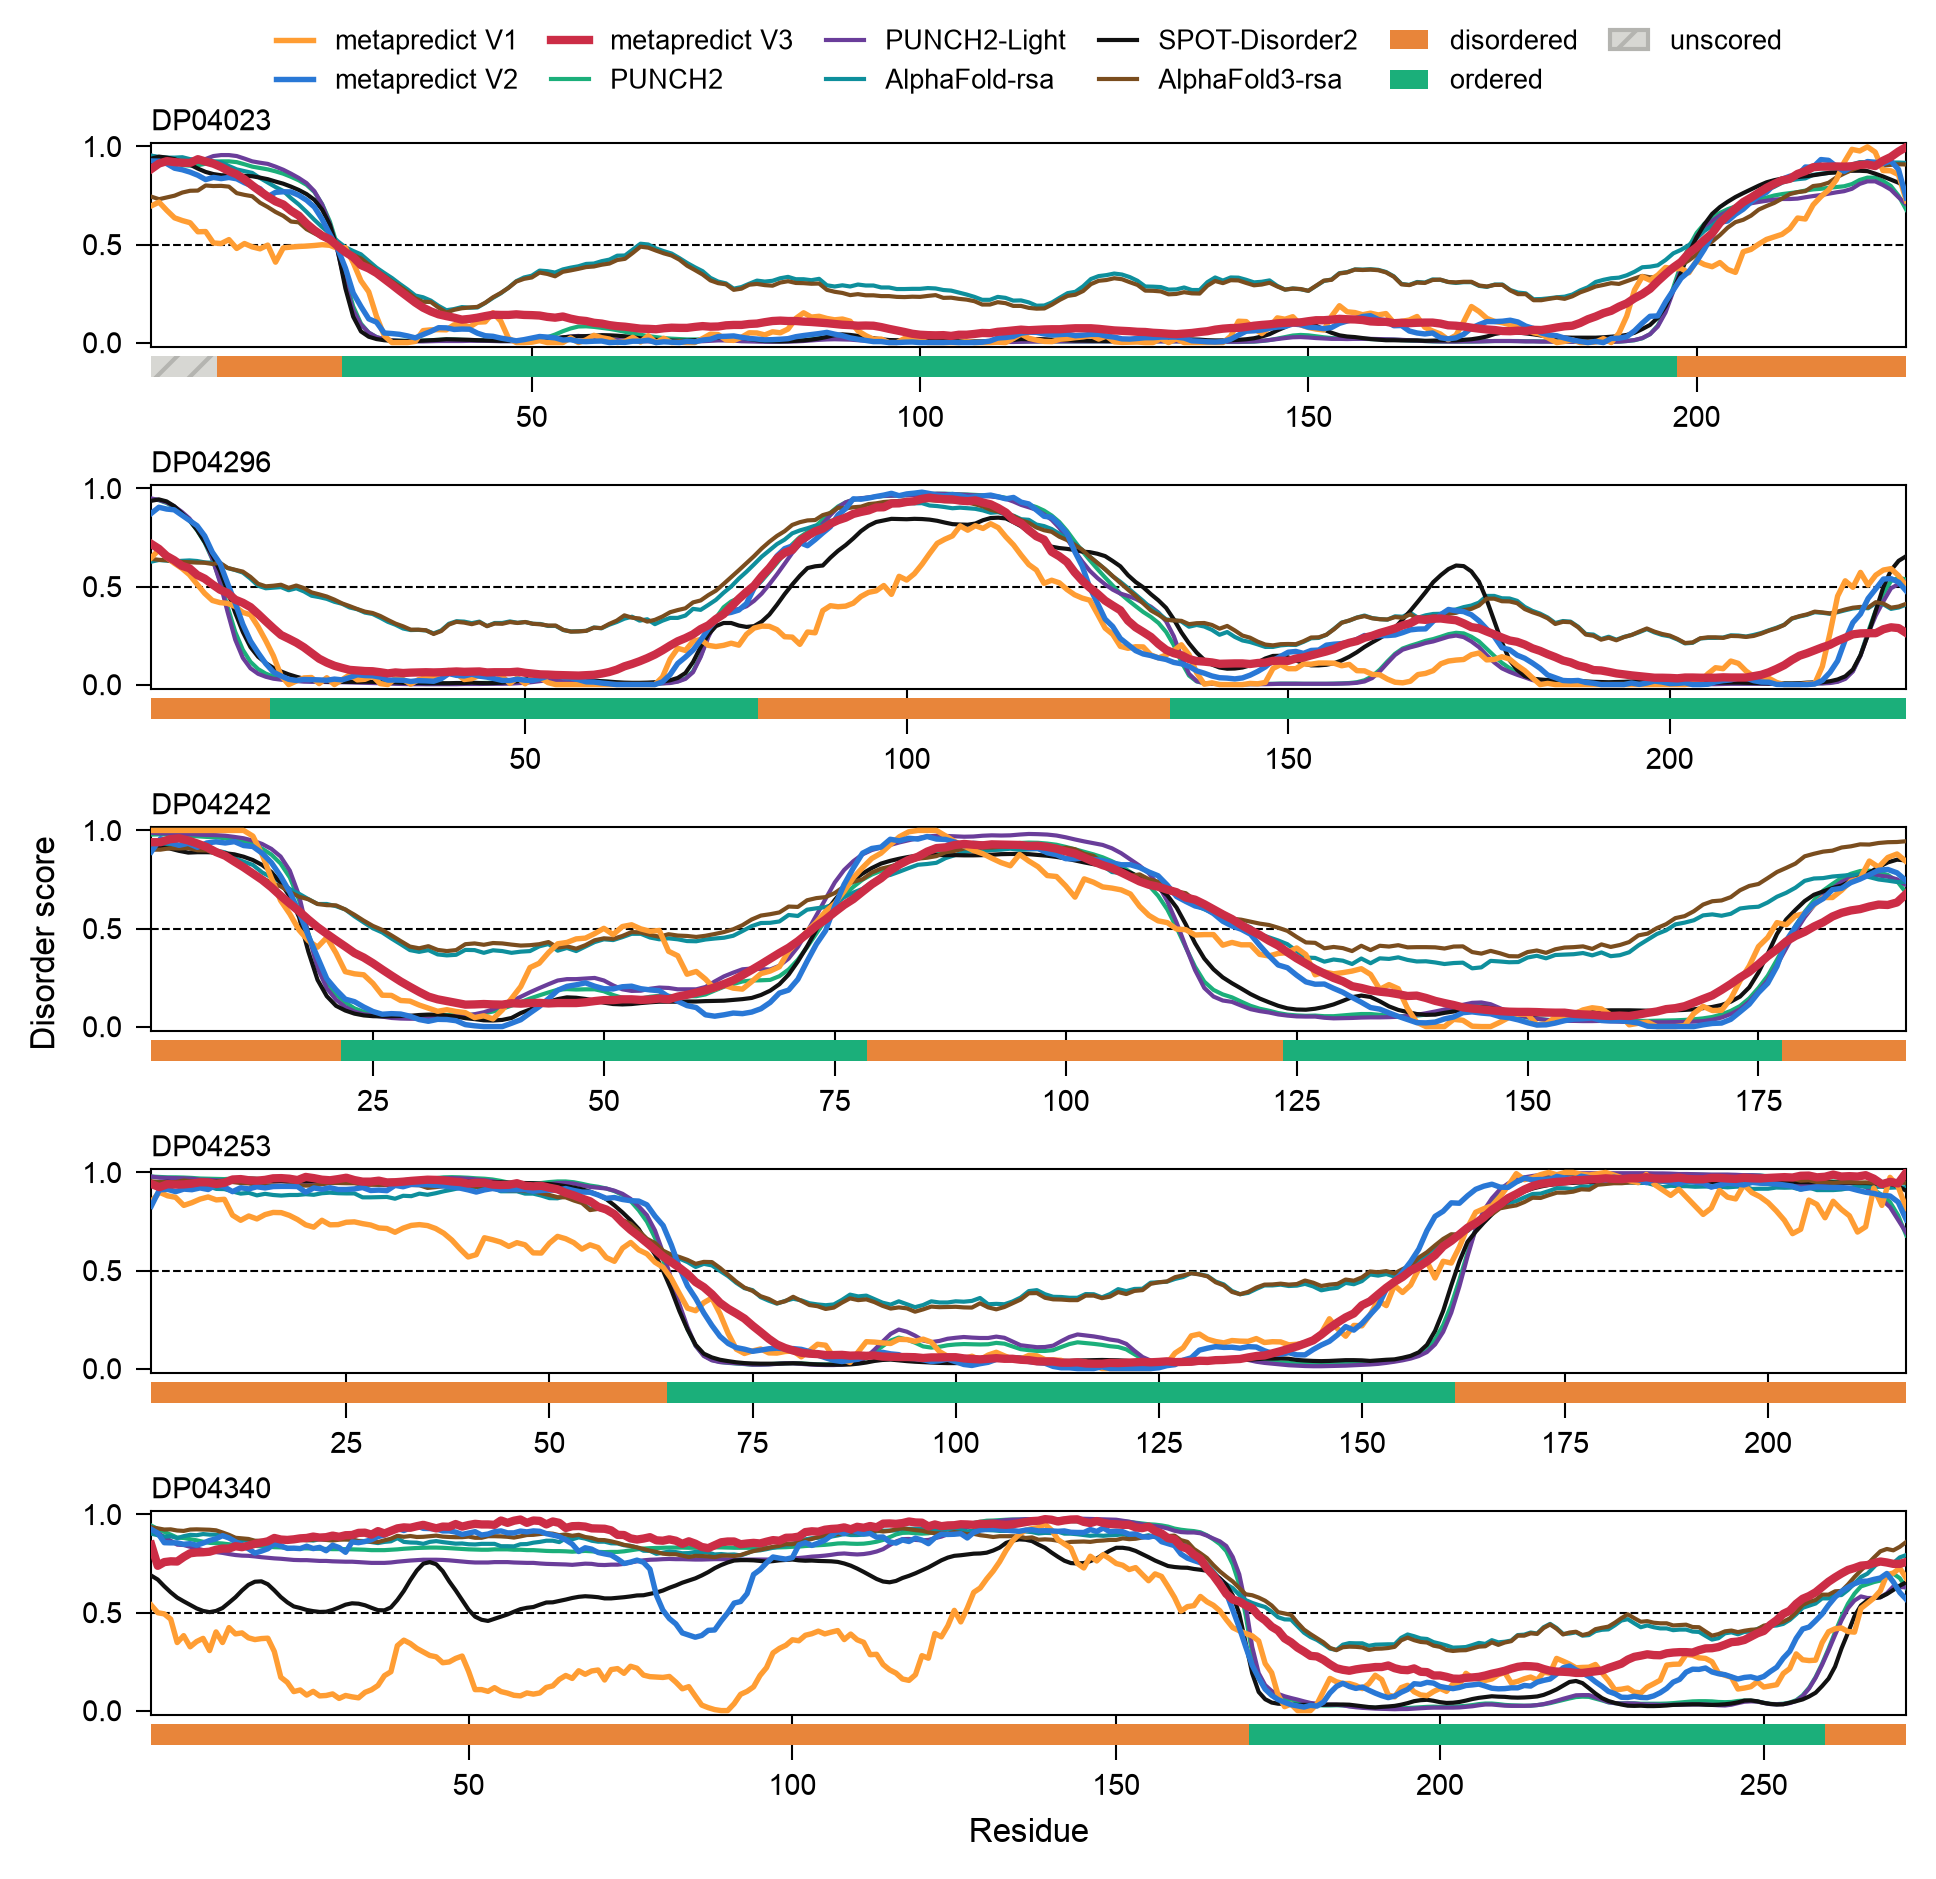

In [3]:
fig = plt.figure(figsize=(TRACK_WIDTH_IN, trace_panel_height(len(SI_PROFILE_TARGETS))), dpi=150)
trace_panel(fig, SI_PROFILE_TARGETS, series, reference, predictions, legend_predictors=True)
save_panel(fig, 'figure_S04')